In [ ]:
# Demo

# Overview
- MNIST dataset
  + Goal: recognizing handwritten digits
  + Input: a 28x28 image
  + Output: class label (0, 1,..., 9)
- Defining an CNN+MLP for MNIST
- Training and evaluating an CNN+MLP

# Import libraries

In [2]:
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.optimizers import SGD

from IPython.display import SVG
# from tensorflow.keras.utils.vis_utils import model_to_dot
from tensorflow.keras.utils import plot_model

import time
import numpy as np
import matplotlib.pyplot as plt

In [3]:
num_classes = 10   # 10 classes: 0, 1,..., 9

# (1) Data

In [4]:
# the data, shuffled and split between train and test sets
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(60000, 28, 28, 1)
x_test = x_test.reshape(10000, 28, 28, 1)
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255
print(x_train.shape[0], 'train samples')
print(x_test.shape[0], 'test samples')

# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

11490434/11490434 [==============================] - 0s 0us/step
60000 train samples
10000 test samples


In [5]:
#   [0, 1, 2]
# 0  1  0  0
# 1  0  1  0
# 2  0  0  1
keras.utils.to_categorical(2, num_classes = 3)

array([0., 0., 1.], dtype=float32)

# (2) Declare model

In [6]:
# 28x28 MNIST image
input_image = Input(shape=(28, 28, 1), name='Input')

# conv, pooling layers + dropout
x = Conv2D(filters=64, kernel_size=(3, 3), padding='same', activation='relu', name='conv1')(input_image)
x = MaxPooling2D(pool_size=(2, 2), name='pool1')(x)
x = Dropout(rate=0.2, name='conv_dropout1')(x)

x = Conv2D(filters=128, kernel_size=(3, 3), padding='same', activation='relu', name='conv2')(x)
x = MaxPooling2D(pool_size=(2, 2), name='pool2')(x)
x = Dropout(rate=0.2, name='conv_dropout2')(x)

x = Conv2D(filters=256, kernel_size=(3, 3), padding='same', activation='relu', name='conv3')(x)
x = MaxPooling2D(pool_size=(2, 2), name='pool3')(x)
x = Dropout(rate=0.2, name='conv_dropout3')(x)

# similar to the MLP example!
# matrix ---> vector
x = Flatten(name='flatten')(x)

# FC layers + dropout
x = Dense(units=512, activation='relu', name='fc1')(x)
x = Dropout(rate=0.2, name='fc_dropout1')(x)

x = Dense(units=512, activation='relu', name='fc2')(x)
x = Dropout(rate=0.2, name='fc_dropout2')(x)

output_label = Dense(units=num_classes, activation='softmax', name='fc3_10ways_softmax')(x)

# define model
model = Model(inputs=input_image, outputs=output_label, name='mnist_mlp')

# print model summary
model.summary()

Model: "mnist_mlp"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input (InputLayer)          [(None, 28, 28, 1)]       0         
                                                                 
 conv1 (Conv2D)              (None, 28, 28, 64)        640       
                                                                 
 pool1 (MaxPooling2D)        (None, 14, 14, 64)        0         
                                                                 
 conv_dropout1 (Dropout)     (None, 14, 14, 64)        0         
                                                                 
 conv2 (Conv2D)              (None, 14, 14, 128)       73856     
                                                                 
 pool2 (MaxPooling2D)        (None, 7, 7, 128)         0         
                                                                 
 conv_dropout2 (Dropout)     (None, 7, 7, 128)         0 

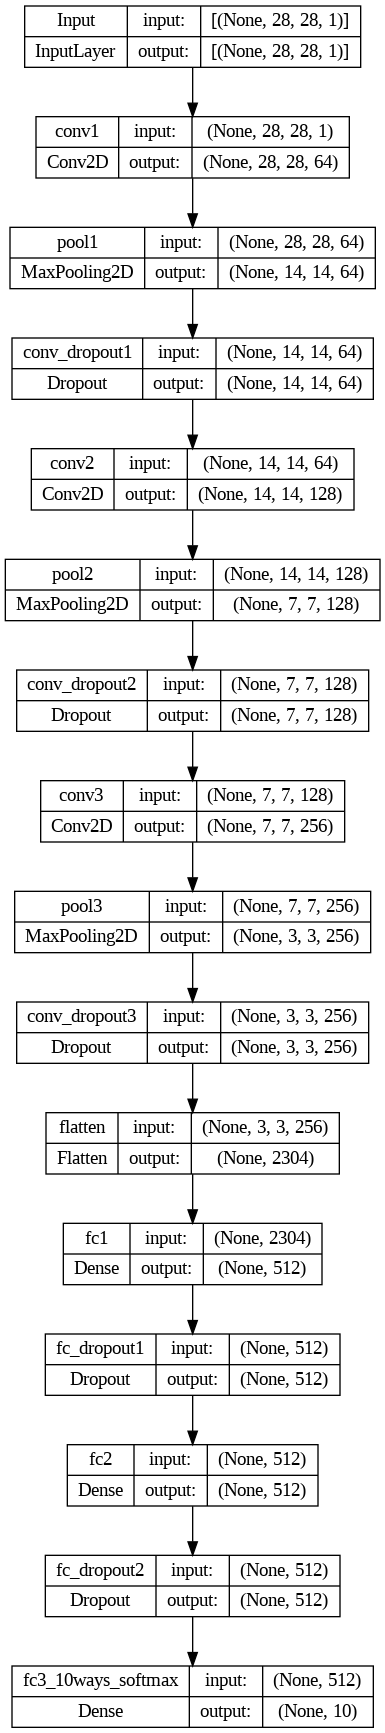

In [7]:
plot_model(model, show_shapes=True)

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [8]:
# declare learning rate, loss function, and model metric
loss = 'categorical_crossentropy'
lr = 0.01
model.compile(loss=loss, optimizer=SGD(lr=lr), metrics=['accuracy'])

# train the model
batch_size = 128
epochs = 30

starting_time = time.time()
history = model.fit(x_train, y_train,
                    validation_data=(x_test, y_test),
                    batch_size=batch_size,
                    epochs=epochs)
print('> training time is %.4f minutes' % ((time.time() - starting_time)/60))

Epoch 1/30
469/469 [==============================] - 17s 14ms/step - loss: 2.1135 - accuracy: 0.2911 - val_loss: 1.1368 - val_accuracy: 0.6920
Epoch 2/30
469/469 [==============================] - 6s 13ms/step - loss: 0.8229 - accuracy: 0.7240 - val_loss: 0.3359 - val_accuracy: 0.9074
Epoch 3/30
469/469 [==============================] - 6s 12ms/step - loss: 0.4273 - accuracy: 0.8609 - val_loss: 0.1965 - val_accuracy: 0.9406
Epoch 4/30
469/469 [==============================] - 6s 12ms/step - loss: 0.2924 - accuracy: 0.9071 - val_loss: 0.1504 - val_accuracy: 0.9525
Epoch 5/30
469/469 [==============================] - 6s 13ms/step - loss: 0.2291 - accuracy: 0.9275 - val_loss: 0.1169 - val_accuracy: 0.9622
Epoch 6/30
469/469 [==============================] - 6s 12ms/step - loss: 0.1937 - accuracy: 0.9382 - val_loss: 0.1043 - val_accuracy: 0.9658
Epoch 7/30
469/469 [==============================] - 6s 13ms/step - loss: 0.1702 - accuracy: 0.9457 - val_loss: 0.0908 - val_accuracy: 0.969

### Training time
- Training time with GTX 1080 is about 4.2231 minutes for 30 epochs
- Training time with Core i7 is around 105.5 minutes for 30 epochs

# (4) Evaluate trained model

In [9]:
score = model.evaluate(x_test, y_test)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

313/313 [==============================] - 1s 3ms/step - loss: 0.0339 - accuracy: 0.9884
Test loss: 0.03391369804739952
Test accuracy: 0.9883999824523926


In [12]:
x_train.shape, y_train.shape, np.argmax(y_train, axis = 1).shape

((60000, 28, 28, 1), (60000, 10), (60000,))

In [16]:
data_org = x_train.reshape(x_train.shape[0], -1)
data_lbl = np.argmax(y_train, axis = 1)
print(data_org.shape, data_lbl.shape)

(60000, 784) (60000,)


In [17]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
org_pca = pca.fit_transform(data_org)

In [18]:
print(org_pca.shape)

(60000, 2)


Text(0.5, 1.0, 'Visualization of MNIST dataset using PCA')

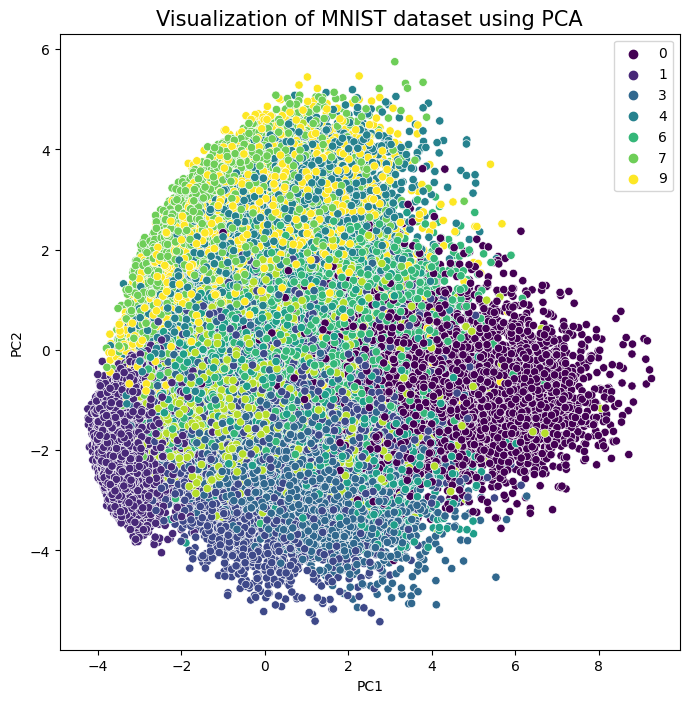

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 8))
sns.scatterplot(x=org_pca[:, 0], y=org_pca[:, 1], hue=data_lbl, palette='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of MNIST dataset using PCA', {'fontsize': 15})

In [ ]:
model.get_layer()

1/1 [==============================] - 0s 187ms/step


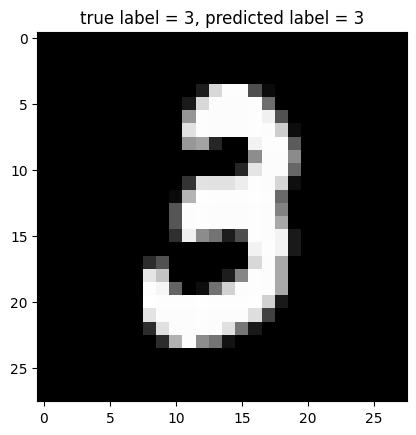

In [12]:
# select a test image randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = np.argmax(y_test[random_test_index])

# predict test image with trained model
pred_label = model.predict(np.expand_dims(test_img, axis=0))
pred_label = np.argmax(pred_label)

plt.imshow(test_img[:, :, 0], cmap='gray')
plt.title('true label = %d, predicted label = %d' % (test_label, pred_label))
plt.show()

In [21]:
model_fc2 = Model(inputs = model.input, outputs = model.get_layer("fc2").output)

In [22]:
y_feat = model_fc2.predict(x_train)

1875/1875 [==============================] - 4s 2ms/step


In [24]:
print(y_feat.shape)

(60000, 512)


In [25]:
from sklearn.decomposition import PCA
pca_fc2 = PCA(n_components=2)
fc2_pca = pca_fc2.fit_transform(y_feat)

In [26]:
print(fc2_pca.shape)

(60000, 2)


Text(0.5, 1.0, 'Visualization of MNIST dataset using PCA')

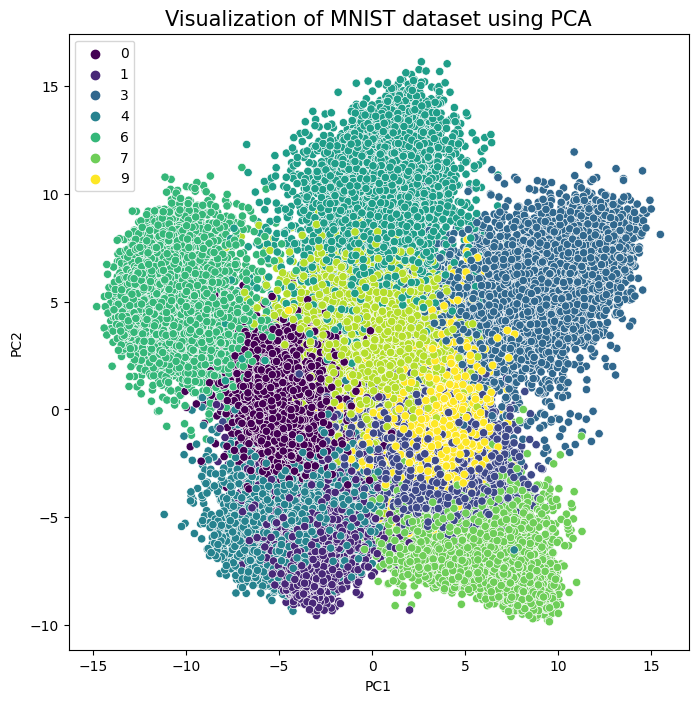

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 8))
sns.scatterplot(x=fc2_pca[:, 0], y=fc2_pca[:, 1], hue=data_lbl, palette='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of MNIST dataset using PCA', {'fontsize': 15})

In [31]:
from tensorflow.keras.layers import GlobalAveragePooling2D

x1 = model.get_layer("pool3").output
x1 = GlobalAveragePooling2D()(x1)

In [33]:
model2 = Model(inputs = model.input, outputs = x1)

In [34]:
y2_feat = model2.predict(x_train)

1875/1875 [==============================] - 4s 2ms/step


In [35]:
print(y2_feat.shape)

(60000, 256)


In [36]:
from sklearn.decomposition import PCA
pca_y2 = PCA(n_components=2)
y2_pca = pca_y2.fit_transform(y2_feat)

Text(0.5, 1.0, 'Visualization of MNIST dataset using PCA')

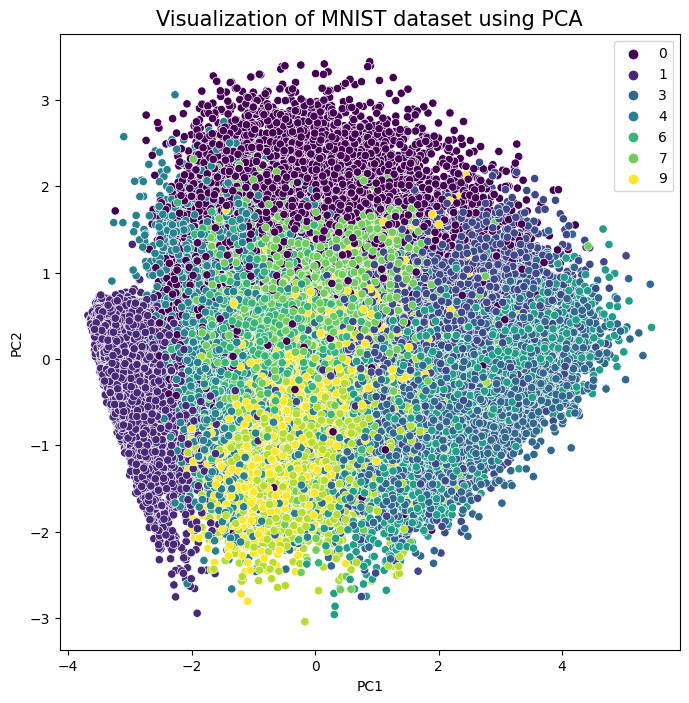

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 8))
sns.scatterplot(x=y2_pca[:, 0], y=y2_pca[:, 1], hue=data_lbl, palette='viridis')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Visualization of MNIST dataset using PCA', {'fontsize': 15})